# Constraint Satisfaction Problem: Graph coloring (Tô màu đồ thị)

**Sinh viên thực hiện:** Ngô Đông Ất – MSSV 3123410014 – Lớp DNT1241  
**Học phần:** Trí tuệ nhân tạo nâng cao – Lab 4: Bài toán thỏa mãn ràng buộc (CSP)  
**Giảng viên:** TS. Đỗ Như Tài – Năm học 2025–2026  
**Công cụ AI đã dùng:** Claude (Anthropic) hỗ trợ viết mã và soạn thảo; kết quả đã được chạy lại và kiểm tra bằng các phép kiểm thử trong notebook.

**Nội dung notebook (khớp với Bài 1–4 của đề Lab 4):**

| Bài | Nội dung |
|---|---|
| 1 | Biểu diễn CSP và sinh đồ thị cần tô màu (Delaunay) |
| 2 | Kiểm tra tính đầy đủ (`complete`) và nhất quán (`consistent`) |
| 3 | Backtracking Search, thứ tự chọn biến (MRV) và thứ tự chọn giá trị (LCV) |
| 4 | Forward Checking, Min-Conflicts và thí nghiệm theo kích thước đồ thị |

Toàn bộ hình được lưu vào thư mục `figures/`, bảng số liệu vào `results/` (đường dẫn tương đối, chạy lại được từ đầu trên máy khác).

## 0. Môi trường và thư viện

In [1]:
import os, sys, time, random, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.spatial import Delaunay
from IPython.display import display, Markdown

sys.setrecursionlimit(20000)               # độ sâu đệ quy = số đỉnh, đặt dư cho đồ thị lớn
FIG_DIR, RES_DIR = 'figures', 'results'    # đường dẫn tương đối, không phụ thuộc máy cá nhân
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path)
    print('Đã lưu hình:', path)

def save_table(df, name):
    path = os.path.join(RES_DIR, name)
    df.to_csv(path, index=False, encoding='utf-8-sig')
    print('Đã lưu bảng:', path)

print('Python', platform.python_version(), '|', platform.system())
print('numpy', np.__version__, '| scipy', scipy.__version__,
      '| matplotlib', matplotlib.__version__, '| pandas', pd.__version__)

Python 3.12.3 | Linux
numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.8 | pandas 3.0.2


# Bài 1. Biểu diễn CSP và sinh đồ thị cần tô màu

## Create Data

Ta tạo một đồ thị phẳng với $n$ đỉnh bằng cách đặt ngẫu nhiên $n$ điểm trong mặt phẳng rồi thực hiện [phép tam giác hóa Delaunay](https://en.wikipedia.org/wiki/Delaunay_triangulation). Hạt giống ngẫu nhiên được cố định (`seed = 1111`, $n = 10$) như notebook gốc để kết quả lặp lại được.

Đã lưu hình: figures/csp_01_do_thi_delaunay_n10.png


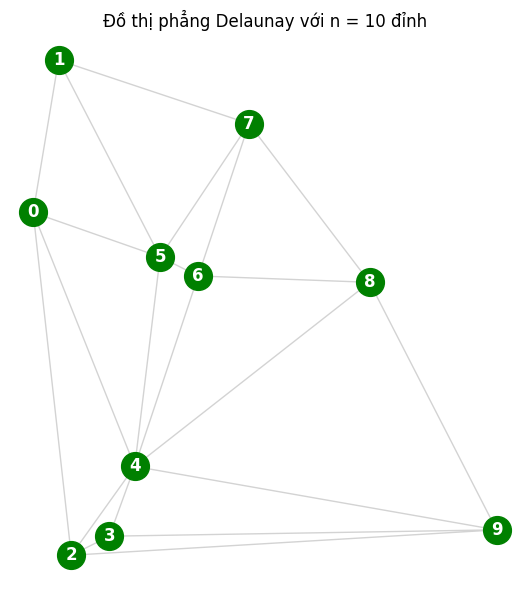

In [2]:
def plot_graph(points, tri, assignment=None, bad_edges=(), mark=(), title=None, ax=None, size=20):
    """Vẽ đồ thị Delaunay. assignment: dict {'đỉnh': 'màu'}; bad_edges: cạnh vi phạm (tô đỏ);
    mark: các đỉnh được khoanh tròn đen."""
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.triplot(points[:, 0], points[:, 1], tri.simplices, color='lightgray', linewidth=1)
    for a, b in bad_edges:
        i, j = int(a), int(b)
        ax.plot(points[[i, j], 0], points[[i, j], 1], color='red', linewidth=3, zorder=2)
    for i in range(len(points)):
        col = assignment[str(i)] if assignment is not None else 'green'
        ax.plot(points[i, 0], points[i, 1], 'o', color=col, markersize=size, zorder=3)
        if size >= 12:
            ax.annotate(i, points[i], color='white', fontsize='large', weight='heavy',
                        horizontalalignment='center', verticalalignment='center', zorder=4)
    for i in mark:
        ax.plot(points[i, 0], points[i, 1], 'o', markersize=size + 9, markerfacecolor='none',
                markeredgecolor='black', markeredgewidth=2, zorder=5)
    ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title)
    if own: plt.tight_layout()

np.random.seed(1111)

# tạo điểm ngẫu nhiên và sắp xếp theo hoành độ (như notebook gốc)
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:, 0])
points = points[o, :]

# tam giác hóa Delaunay
tri = Delaunay(points)

plot_graph(points, tri, title=f'Đồ thị phẳng Delaunay với n = {n} đỉnh')
save_fig('csp_01_do_thi_delaunay_n10.png')
plt.show()

Phép tam giác hóa được chuyển thành danh sách `neighbors`: hàng thứ $k$ chứa chỉ số các đỉnh láng giềng của đỉnh $k$ (xem [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)).

In [3]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []
for k in range(len(indptr) - 1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k + 1]]))

df_neighbors = pd.DataFrame({
    'Đỉnh': range(n),
    'Danh sách neighbors': [[int(v) for v in nb] for nb in neighbors],
    'Bậc': [len(nb) for nb in neighbors]})
display(df_neighbors)
save_table(df_neighbors, 'csp_bai1_neighbors_n10.csv')

,Đỉnh,Danh sách neighbors,Bậc
0,0,"[1, 2, 4, 5]",4
1,1,"[0, 5, 7]",3
2,2,"[0, 3, 4, 9]",4
3,3,"[2, 4, 9]",3
4,4,"[0, 2, 3, 5, 6, 8, 9]",7
5,5,"[0, 1, 4, 6, 7]",5
6,6,"[4, 5, 7, 8]",4
7,7,"[1, 5, 6, 8]",4
8,8,"[4, 6, 7, 9]",4
9,9,"[2, 3, 4, 8]",4


Đã lưu bảng: results/csp_bai1_neighbors_n10.csv


## Define CSP

Một CSP gồm ba thành phần $(X, D, C)$:

* **Biến** $X = \{0, 1, \dots, n-1\}$: mỗi đỉnh của đồ thị là một biến (lưu dưới dạng chuỗi `'0'`, `'1'`, …).
* **Miền giá trị** $D_i$: tập màu. Khảo sát hai trường hợp: 4 màu `{red, blue, green, orange}` và 3 màu `{red, blue, green}`.
* **Ràng buộc** $C_{ij}$: `color(i) != color(j)` với mọi cạnh $(i, j)$ của đồ thị – các ràng buộc nhị phân "khác nhau".

**Vì sao chỉ tạo ràng buộc cho cạnh $i < j$?** Quan hệ "khác màu" có tính đối xứng, nên `C(i, j)` và `C(j, i)` là cùng một ràng buộc. Trong `neighbors`, mỗi cạnh xuất hiện hai lần (một lần ở đỉnh $i$, một lần ở đỉnh $j$); điều kiện `i < j` giữ lại đúng một bản, nên số ràng buộc bằng đúng số cạnh $= \frac{1}{2}\sum_i \deg(i)$ và không bị kiểm tra lặp.

Bài toán được lưu bằng một `dict` gồm danh sách biến, `dict` miền giá trị của từng biến và danh sách các cặp biến bị ràng buộc.

In [4]:
def make_csp(neighbors, colors):
    variables = [str(v) for v in range(len(neighbors))]
    domains = {v: list(colors) for v in variables}
    constraints = [(str(i), str(j)) for i in range(len(neighbors))
                   for j in neighbors[i] if i < j]
    return {'variables': variables, 'domains': domains, 'constraints': constraints}

def adjacency(csp):
    """Tập láng giềng của mỗi biến, dựng từ danh sách ràng buộc."""
    adj = {v: set() for v in csp['variables']}
    for a, b in csp['constraints']:
        adj[a].add(b)
        adj[b].add(a)
    return adj

COLORS4 = ['red', 'blue', 'green', 'orange']
COLORS3 = COLORS4[:3]

csp = make_csp(neighbors, COLORS4)      # miền 4 màu (như notebook gốc)
csp3 = make_csp(neighbors, COLORS3)     # miền 3 màu

print('Biến      :', csp['variables'])
print('Miền (4 màu):', csp['domains']['0'])
print('Miền (3 màu):', csp3['domains']['0'])
print('Số ràng buộc (= số cạnh):', len(csp['constraints']))
print('Ràng buộc :', csp['constraints'])
assert len(csp['constraints']) == sum(len(nb) for nb in neighbors) // 2   # mỗi cạnh đúng một ràng buộc

Biến      : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Miền (4 màu): ['red', 'blue', 'green', 'orange']
Miền (3 màu): ['red', 'blue', 'green']
Số ràng buộc (= số cạnh): 21
Ràng buộc : [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')]


## Phép gán đầy đủ và phép gán hợp lệ

* **Phép gán đầy đủ (complete):** mọi biến đều có giá trị.
* **Phép gán hợp lệ / nhất quán (consistent):** không có ràng buộc nào giữa các biến *đã được gán* bị vi phạm.
* **Nghiệm của CSP:** phép gán *vừa đầy đủ vừa hợp lệ*.

Để thấy sự khác nhau, ta đếm bằng vét cạn: trong tất cả $k^n$ phép gán đầy đủ, có bao nhiêu phép gán hợp lệ (nghiệm)?

In [5]:
def count_proper_colorings(csp, k):
    """Vét cạn tất cả k^n phép gán đầy đủ; đếm số phép gán không vi phạm ràng buộc nào."""
    n_vars = len(csp['variables'])
    grid = np.indices((k,) * n_vars, dtype=np.int8).reshape(n_vars, -1)
    ok = np.ones(grid.shape[1], dtype=bool)
    for a, b in csp['constraints']:
        ok &= grid[int(a)] != grid[int(b)]
    return grid.shape[1], int(ok.sum())

rows = []
for k, c in [(4, csp), (3, csp3)]:
    total, valid = count_proper_colorings(c, k)
    rows.append({'Số màu |D|': k, 'Số phép gán đầy đủ (k^n)': total,
                 'Số phép gán đầy đủ và hợp lệ (nghiệm)': valid,
                 'Tỷ lệ hợp lệ (%)': round(100 * valid / total, 4)})
df_count = pd.DataFrame(rows)
display(df_count)
save_table(df_count, 'csp_bai1_dem_nghiem_n10.csv')

,Số màu |D|,Số phép gán đầy đủ (k^n),Số phép gán đầy đủ và hợp lệ (nghiệm),Tỷ lệ hợp lệ (%)
0,4,1048576,480,0.0458
1,3,59049,0,0.0000


Đã lưu bảng: results/csp_bai1_dem_nghiem_n10.csv


**Nhận xét Bài 1.**

* Mô hình CSP: $X=\{0,\dots,9\}$, $D_i=\{\text{red, blue, green, orange}\}$ (hoặc 3 màu), $C_{ij}$: `color(i) != color(j)` cho 21 cạnh của đồ thị. Tổng bậc các đỉnh là 42 nên số cạnh là $42/2 = 21$, khớp với số ràng buộc – chứng tỏ điều kiện `i < j` giữ đúng một ràng buộc cho mỗi cạnh.
* Với 4 màu có $4^{10}=1\,048\,576$ phép gán **đầy đủ**, nhưng chỉ có **480** phép (≈ 0,046 %) là **hợp lệ** (nghiệm). Với 3 màu có $3^{10}=59\,049$ phép gán đầy đủ và **không có phép nào hợp lệ**: bài toán 3 màu trên đồ thị này **vô nghiệm**. Như vậy "đầy đủ" chỉ nói rằng mọi biến đã có giá trị, còn "hợp lệ" mới nói rằng không ràng buộc nào bị vi phạm.

# Bài 2. Kiểm tra tính đầy đủ và nhất quán

## Check Completeness and Consistency

`assignment` là một `dict`; biến đã gán có khóa là tên biến, nên `{}` là phép gán rỗng.

In [6]:
def complete(assignment, csp):
    return all([v in assignment.keys() for v in csp['variables']])

def consistent(assignment, csp):
    for constr in csp['constraints']:
        if constr[0] in assignment.keys() and constr[1] in assignment.keys():
            if assignment[constr[0]] == assignment[constr[1]]:
                return False
    return True

print("complete({}, csp)   =", complete({}, csp))
print("consistent({}, csp) =", consistent({}, csp))

complete({}, csp)   = False
consistent({}, csp) = True


### Các ca kiểm thử

Ta lấy một cạnh bất kỳ `(a, b)` của đồ thị để dựng các phép gán, và ghi rõ kết quả mong đợi (suy ra từ định nghĩa) trước khi chạy hàm. Ca T5 dùng phép tô tham lam (mỗi đỉnh nhận màu đầu tiên chưa dùng bởi láng giềng đã tô) để có một phép gán đầy đủ và hợp lệ.

In [7]:
def greedy_assignment(csp):
    adj = adjacency(csp)
    assignment = {}
    for v in csp['variables']:
        used = {assignment[u] for u in adj[v] if u in assignment}
        assignment[v] = next(c for c in csp['domains'][v] if c not in used)
    return assignment

a, b = csp['constraints'][0]          # một cạnh bất kỳ
tests = [
    # (tên ca kiểm thử, phép gán, complete mong đợi, consistent mong đợi)
    ('T1: phép gán rỗng',                         {},                                   False, True),
    ('T2: một phần, hai đỉnh kề khác màu',        {a: 'red', b: 'blue'},                False, True),
    ('T3: một phần, hai đỉnh kề cùng màu',        {a: 'red', b: 'red'},                 False, False),
    ('T4: đầy đủ, mọi đỉnh cùng màu đỏ',          {v: 'red' for v in csp['variables']}, True,  False),
    ('T5: đầy đủ, tô tham lam (hợp lệ)',          greedy_assignment(csp),               True,  True),
]

rows = []
for name, asg, exp_c, exp_k in tests:
    c_val, k_val = complete(asg, csp), consistent(asg, csp)
    rows.append({'Ca kiểm thử': name,
                 'complete (mong đợi)': exp_c, 'complete (thực tế)': c_val,
                 'consistent (mong đợi)': exp_k, 'consistent (thực tế)': k_val,
                 'Kết quả': 'ĐẠT' if (c_val == exp_c and k_val == exp_k) else 'LỖI'})
df_tests = pd.DataFrame(rows)
display(df_tests)
save_table(df_tests, 'csp_bai2_ca_kiem_thu.csv')
assert (df_tests['Kết quả'] == 'ĐẠT').all()

,Ca kiểm thử,complete (mong đợi),complete (thực tế),consistent (mong đợi),consistent (thực tế),Kết quả
0,T1: phép gán rỗng,False,False,True,True,ĐẠT
1,"T2: một phần, hai đỉnh kề khác màu",False,False,True,True,ĐẠT
2,"T3: một phần, hai đỉnh kề cùng màu",False,False,False,False,ĐẠT
3,"T4: đầy đủ, mọi đỉnh cùng màu đỏ",True,True,False,False,ĐẠT
4,"T5: đầy đủ, tô tham lam (hợp lệ)",True,True,True,True,ĐẠT


Đã lưu bảng: results/csp_bai2_ca_kiem_thu.csv


**Nhận xét Bài 2.**

* T3 cho thấy một phép gán **chưa đầy đủ** vẫn có thể **không hợp lệ**; T4 cho thấy một phép gán **đầy đủ** vẫn có thể **không hợp lệ**; T1, T2 cho thấy phép gán rỗng hoặc một phần hợp lệ vẫn **chưa phải nghiệm**. Vì vậy `complete()` **không** đồng nghĩa với `consistent()`: hai hàm trả lời hai câu hỏi độc lập.
* Phép gán chỉ là **nghiệm CSP** khi cả hai đều đúng (T5). Trong backtracking, `consistent` dùng để cắt nhánh sớm (phép gán từng phần đã vi phạm thì mọi mở rộng của nó đều vi phạm), còn `complete` là điều kiện dừng của đệ quy.
* Dạng lưu trữ `csp` gồm `variables` (danh sách tên biến), `domains` (từ điển biến → danh sách giá trị) và `constraints` (danh sách các cặp biến phải khác giá trị). `assignment` là từ điển chỉ chứa các biến đã gán: phép gán từng phần là `assignment` thiếu biến; nghiệm là `assignment` có đủ biến và không vi phạm ràng buộc nào.

# Bài 3. Backtracking Search và thứ tự chọn biến

## Implement Simple Backtracking Search

Phiên bản gốc: chọn biến chưa gán *đầu tiên* và thử các giá trị theo thứ tự trong miền. Biến toàn cục `COUNT` đếm số nút (lời gọi `backtrack`) được kiểm tra.

In [8]:
def select_unassigned_var(assignment, csp):
    # phiên bản gốc: chọn biến chưa gán đầu tiên theo thứ tự trong danh sách biến
    if complete(assignment, csp): return None
    return csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]]

VERBOSE = False
COUNT = 0

# trả về None nếu thất bại
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    assignment = backtrack({}, csp)
    print(f"Checked nodes: {COUNT}")
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    COUNT += 1
    if complete(assignment, csp):
        return assignment
    var = select_unassigned_var(assignment, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        if VERBOSE: print(f"Checking: {assignment}")
        if consistent(assignment, csp):
            result = backtrack(assignment, csp)
            if not result is None:
                return result
        del assignment[var]
    if VERBOSE: print(f"Backtracking")
    return None

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =",
      select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


## Run Backtracking Search on the Random Problem

Chạy trên đồ thị $n = 10$ với 4 màu, đo thời gian bằng `time.perf_counter()` và theo dõi `COUNT`.

In [9]:
t0 = time.perf_counter()
res = backtrack_search(csp)
t_orig = time.perf_counter() - t0
COUNT_ORIG = COUNT
print(f"Thời gian chạy: {t_orig * 1000:.3f} ms | COUNT = {COUNT_ORIG}")
display(res)
assert complete(res, csp) and consistent(res, csp)    # nghiệm = đầy đủ và hợp lệ

Checked nodes: 11
Thời gian chạy: 0.229 ms | COUNT = 11


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

**Trực quan hóa kết quả.** Đoạn vẽ trong notebook gốc lấy màu bằng `list(res.values())[i]`, chỉ đúng khi các biến được gán theo thứ tự $0, 1, 2, \dots$. Khi đổi sang MRV, thứ tự gán thay đổi nên cách lấy này sẽ tô sai màu; vì vậy ta vẽ theo khóa `assignment[str(i)]`.

Đã lưu hình: figures/csp_02_to_mau_backtracking_4mau_n10.png


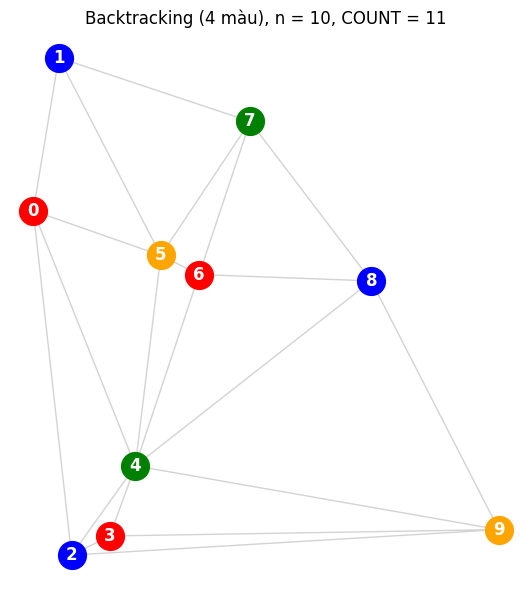

In [10]:
plot_graph(points, tri, res, title=f'Backtracking (4 màu), n = {n}, COUNT = {COUNT_ORIG}')
save_fig('csp_02_to_mau_backtracking_4mau_n10.png')
plt.show()

## Thứ tự chọn biến (MRV) và thứ tự chọn giá trị (LCV)

Để cài đặt các heuristic mà vẫn so sánh công bằng với bản gốc, ta viết một bộ giải tổng quát `solve(...)` với các thành phần thay thế được:

* `legal_values(var, ...)`: các giá trị **còn hợp lệ** của biến, tức là chưa bị trùng với láng giềng đã gán.
* **MRV (Minimum Remaining Values)**: chọn biến chưa gán có *ít giá trị hợp lệ nhất* (hòa thì chọn biến có nhiều láng giềng chưa gán nhất – heuristic bậc). Biến "khó" nhất được xử lý trước nên thất bại được phát hiện sớm.
* **LCV (Least Constraining Value)**: thử trước giá trị *loại bỏ ít lựa chọn nhất* của các láng giềng chưa gán, để giữ nhiều khả năng cho phần còn lại.
* **Forward Checking** (tham số `forward_checking`, dùng ở Bài 4): sau khi gán màu cho một đỉnh, loại màu đó khỏi miền các láng giềng chưa gán; nếu một miền rỗng thì cắt nhánh ngay; khi quay lui, hoàn tác các miền đã bị loại.

`solve` trả về trạng thái: `solution` (tìm được nghiệm), `unsat` (duyệt hết không gian, **chứng minh vô nghiệm**) hoặc `limit` (hết giới hạn số nút – chưa kết luận được). Ghi nhận hai chỉ số: `nodes` (= `COUNT`, số lời gọi đệ quy) và `assigns` (số lần gán thử một cặp biến–giá trị).

In [11]:
class NodeLimit(Exception):
    pass

def legal_values(var, assignment, domains, adj):
    used = {assignment[u] for u in adj[var] if u in assignment}
    return [c for c in domains[var] if c not in used]

# ---- chọn biến ----
def select_var_first(assignment, csp, domains, adj):
    for v in csp['variables']:
        if v not in assignment:
            return v

def select_var_mrv(assignment, csp, domains, adj):
    best, best_key = None, None
    for v in csp['variables']:
        if v in assignment: continue
        # khóa: (số giá trị hợp lệ còn lại, -số láng giềng chưa gán) -> nhỏ nhất là tốt nhất
        key = (len(legal_values(v, assignment, domains, adj)),
               -sum(1 for u in adj[v] if u not in assignment))
        if best_key is None or key < best_key:
            best, best_key = v, key
    return best

# ---- chọn giá trị ----
def order_default(var, assignment, domains, adj):
    return legal_values(var, assignment, domains, adj)

def order_lcv(var, assignment, domains, adj):
    vals = legal_values(var, assignment, domains, adj)
    free = [u for u in adj[var] if u not in assignment]
    legal_u = {u: set(legal_values(u, assignment, domains, adj)) for u in free}
    # chi phí của màu c = số láng giềng chưa gán đang còn dùng được c (mỗi láng giềng mất 1 giá trị)
    return sorted(vals, key=lambda c: sum(1 for u in free if c in legal_u[u]))

def solve(csp, select_var=select_var_first, order_values=order_default,
          forward_checking=False, node_limit=20000):
    adj = adjacency(csp)
    domains = {v: list(csp['domains'][v]) for v in csp['variables']}
    rank = {c: i for i, c in enumerate(csp['domains'][csp['variables'][0]])}   # để khôi phục thứ tự miền
    n_vars = len(csp['variables'])
    stats = {'nodes': 0, 'assigns': 0}
    assignment = {}

    def rec():
        stats['nodes'] += 1                                   # COUNT: số nút được kiểm tra
        if node_limit and stats['nodes'] > node_limit:
            raise NodeLimit
        if len(assignment) == n_vars:
            return True
        var = select_var(assignment, csp, domains, adj)
        for val in order_values(var, assignment, domains, adj):
            stats['assigns'] += 1
            assignment[var] = val
            pruned, ok = [], True
            if forward_checking:                              # --- Bài 4: Forward Checking ---
                for u in adj[var]:
                    if u not in assignment and val in domains[u]:
                        domains[u].remove(val)
                        pruned.append(u)
                        if not domains[u]:                    # miền rỗng -> cắt nhánh sớm
                            ok = False
                            break
            if ok and rec():
                return True
            for u in pruned:                                  # hoàn tác miền khi quay lui
                domains[u].append(val)
                domains[u].sort(key=rank.get)
            del assignment[var]
        return False

    t0 = time.perf_counter()
    try:
        found = rec()
        status = 'solution' if found else 'unsat'
    except NodeLimit:
        found, status = False, 'limit'
    dt = time.perf_counter() - t0
    return {'assignment': dict(assignment) if found else None, 'status': status,
            'nodes': stats['nodes'], 'assigns': stats['assigns'], 'time': dt}

# Kiểm tra: cấu hình (first, default, không FC) phải tái tạo đúng COUNT của bản gốc
r_check = solve(csp, node_limit=None)
assert r_check['nodes'] == COUNT_ORIG and r_check['assignment'] == res
print('Bản tổng quát tái tạo đúng bản gốc: COUNT =', r_check['nodes'])

Bản tổng quát tái tạo đúng bản gốc: COUNT = 11


In [12]:
BT_CONFIGS = {
    'Backtracking (gốc)':  dict(select_var=select_var_first, order_values=order_default, forward_checking=False),
    '+ MRV':               dict(select_var=select_var_mrv,   order_values=order_default, forward_checking=False),
    '+ LCV':               dict(select_var=select_var_first, order_values=order_lcv,     forward_checking=False),
    '+ MRV + LCV':         dict(select_var=select_var_mrv,   order_values=order_lcv,     forward_checking=False),
}
FC_CONFIGS = {
    'Forward Checking':    dict(select_var=select_var_first, order_values=order_default, forward_checking=True),
    'FC + MRV':            dict(select_var=select_var_mrv,   order_values=order_default, forward_checking=True),
    'FC + MRV + LCV':      dict(select_var=select_var_mrv,   order_values=order_lcv,     forward_checking=True),
}
ALL_CONFIGS = {**BT_CONFIGS, **FC_CONFIGS}

def run_configs(csp, configs, node_limit=20000, repeat=20):
    rows = []
    for name, kw in configs.items():
        r = solve(csp, node_limit=node_limit, **kw)
        ts = [solve(csp, node_limit=node_limit, **kw)['time'] for _ in range(repeat)]   # thời gian trung bình
        valid = '-'
        if r['status'] == 'solution':
            valid = complete(r['assignment'], csp) and consistent(r['assignment'], csp)
        rows.append({'Thuật toán': name, 'Kết quả': r['status'], 'COUNT (nút)': r['nodes'],
                     'Số lần gán thử': r['assigns'], 'Thời gian (ms)': round(1000 * np.mean(ts), 3),
                     'Nghiệm hợp lệ': valid})
    return pd.DataFrame(rows)

df_bt = run_configs(csp, BT_CONFIGS)
display(Markdown('**Đồ thị n = 10, 4 màu – các biến thể Backtracking (chưa dùng Forward Checking)**'))
display(df_bt)
save_table(df_bt, 'csp_bai3_so_sanh_backtracking_n10_4mau.csv')

**Đồ thị n = 10, 4 màu – các biến thể Backtracking (chưa dùng Forward Checking)**

,Thuật toán,Kết quả,COUNT (nút),Số lần gán thử,Thời gian (ms),Nghiệm hợp lệ
0,Backtracking (gốc),solution,11,10,0.013,True
1,+ MRV,solution,11,10,0.081,True
2,+ LCV,solution,11,10,0.051,True
3,+ MRV + LCV,solution,11,10,0.112,True


Đã lưu bảng: results/csp_bai3_so_sanh_backtracking_n10_4mau.csv


Trên đồ thị $n = 10$ chỉ có 10–11 nút nên khác biệt khó thấy. Để minh họa ảnh hưởng của thứ tự chọn biến, ta so sánh trên một đồ thị lớn hơn ($n = 40$) mà các đỉnh được **đánh số ngẫu nhiên** (không sắp theo hoành độ như notebook gốc – cách sắp theo hoành độ vô tình tạo ra một thứ tự quét rất thuận lợi cho "chọn biến đầu tiên").

In [13]:
def make_instance(n, seed, order='random'):
    """Sinh đồ thị Delaunay ngẫu nhiên. order='x': đánh số đỉnh theo hoành độ (như notebook gốc);
    order='random': đánh số ngẫu nhiên."""
    rng = np.random.default_rng(seed)
    pts = rng.random((n, 2)) * 100
    if order == 'x':
        pts = pts[np.argsort(pts[:, 0])]
    tri_ = Delaunay(pts)
    indptr_, indices_ = tri_.vertex_neighbor_vertices
    nbs = [np.sort(indices_[indptr_[k]:indptr_[k + 1]]) for k in range(n)]
    return pts, tri_, nbs

def odd_interior_vertices(tri_, nbs):
    """Đỉnh nằm trong (không thuộc bao lồi) có bậc lẻ: nếu tồn tại thì đồ thị chắc chắn KHÔNG tô được 3 màu."""
    hull = set(int(v) for v in tri_.convex_hull.ravel())
    return [v for v in range(len(nbs)) if v not in hull and len(nbs[v]) % 2 == 1]

pts40, tri40, nb40 = make_instance(40, seed=40001, order='random')
csp40 = make_csp(nb40, COLORS4)
print('Đồ thị n = 40: số cạnh =', len(csp40['constraints']))
df_bt40 = run_configs(csp40, BT_CONFIGS)
display(Markdown('**Đồ thị n = 40 (đánh số ngẫu nhiên), 4 màu – các biến thể Backtracking**'))
display(df_bt40)
save_table(df_bt40, 'csp_bai3_so_sanh_backtracking_n40_4mau.csv')

Đồ thị n = 40: số cạnh = 109


**Đồ thị n = 40 (đánh số ngẫu nhiên), 4 màu – các biến thể Backtracking**

,Thuật toán,Kết quả,COUNT (nút),Số lần gán thử,Thời gian (ms),Nghiệm hợp lệ
0,Backtracking (gốc),limit,20001,20000,34.029,-
1,+ MRV,solution,41,40,1.905,True
2,+ LCV,limit,20001,20000,96.976,-
3,+ MRV + LCV,solution,52,51,2.044,True


Đã lưu bảng: results/csp_bai3_so_sanh_backtracking_n40_4mau.csv


**Nhận xét Bài 3.**

* Trên đồ thị $n=10$ (đánh số theo hoành độ), mọi biến thể đều có `COUNT = 11` $= n+1$: không phải quay lui lần nào, vì thứ tự "biến chưa gán đầu tiên" đã là một thứ tự quét thuận lợi và 4 màu rất dễ. Khác biệt chỉ thấy ở thời gian: mỗi nút của MRV và LCV tốn thêm công tính toán nên chậm hơn bản gốc.
* Trên đồ thị $n=40$ đánh số ngẫu nhiên: **Backtracking gốc và LCV đơn lẻ chạm giới hạn 20 000 nút** mà chưa tìm được nghiệm, còn **MRV chỉ cần 41 nút** (40 biến + nút gốc, tức là gần như không quay lui) và MRV + LCV cần 52 nút. MRV chọn biến "khó nhất" (ít màu hợp lệ nhất) trước nên mâu thuẫn bị phát hiện sớm, ở tầng nông của cây tìm kiếm; thứ tự gốc thì để các đỉnh bị ràng buộc chặt lại cuối cùng, dẫn đến thất bại sâu và quay lui lặp đi lặp lại trên cùng một lỗi.
* **LCV không cải thiện** trong thí nghiệm này: đứng một mình nó không giúp (vẫn chạm giới hạn), kết hợp với MRV còn nhỉnh hơn một chút (52 so với 41 nút). Với ràng buộc "khác màu" và 4 màu, các màu hợp lệ gần như tương đương nhau cho đến khi miền sắp cạn, nên thứ tự chọn **biến** quan trọng hơn nhiều so với thứ tự chọn **giá trị**.

# Bài 4. Forward Checking và Min-Conflicts

## Forward Checking

Forward Checking đã được cài đặt trong `solve(..., forward_checking=True)`: sau mỗi phép gán, màu vừa dùng bị loại khỏi miền của các láng giềng chưa gán; nếu có miền rỗng thì quay lui ngay mà không cần đi sâu hơn; khi quay lui, các miền được hoàn tác. So sánh trên cùng các đồ thị:

In [14]:
df_fc = run_configs(csp, {**BT_CONFIGS, **FC_CONFIGS})
display(Markdown('**Đồ thị n = 10, 4 màu – Backtracking và Forward Checking**'))
display(df_fc)
save_table(df_fc, 'csp_bai4_so_sanh_fc_n10_4mau.csv')

df_fc40 = run_configs(csp40, {**BT_CONFIGS, **FC_CONFIGS})
display(Markdown('**Đồ thị n = 40 (đánh số ngẫu nhiên), 4 màu – Backtracking và Forward Checking**'))
display(df_fc40)
save_table(df_fc40, 'csp_bai4_so_sanh_fc_n40_4mau.csv')

# Trường hợp 3 màu trên đồ thị n = 10: có nghiệm hay không?
df_fc3 = run_configs(csp3, ALL_CONFIGS)
display(Markdown('**Đồ thị n = 10, 3 màu – trạng thái `unsat` nghĩa là đã duyệt hết và chứng minh vô nghiệm**'))
display(df_fc3)
save_table(df_fc3, 'csp_bai4_so_sanh_fc_n10_3mau.csv')

**Đồ thị n = 10, 4 màu – Backtracking và Forward Checking**

,Thuật toán,Kết quả,COUNT (nút),Số lần gán thử,Thời gian (ms),Nghiệm hợp lệ
0,Backtracking (gốc),solution,11,10,0.023,True
1,+ MRV,solution,11,10,0.073,True
2,+ LCV,solution,11,10,0.049,True
3,+ MRV + LCV,solution,11,10,0.173,True
4,Forward Checking,solution,11,10,0.015,True
5,FC + MRV,solution,11,10,0.082,True
6,FC + MRV + LCV,solution,11,10,0.119,True


Đã lưu bảng: results/csp_bai4_so_sanh_fc_n10_4mau.csv


**Đồ thị n = 40 (đánh số ngẫu nhiên), 4 màu – Backtracking và Forward Checking**

,Thuật toán,Kết quả,COUNT (nút),Số lần gán thử,Thời gian (ms),Nghiệm hợp lệ
0,Backtracking (gốc),limit,20001,20000,44.895,-
1,+ MRV,solution,41,40,1.149,True
2,+ LCV,limit,20001,20000,107.335,-
3,+ MRV + LCV,solution,52,51,2.670,True
4,Forward Checking,solution,12903,20481,42.863,True
5,FC + MRV,solution,41,40,1.184,True
6,FC + MRV + LCV,solution,50,51,1.642,True


Đã lưu bảng: results/csp_bai4_so_sanh_fc_n40_4mau.csv


**Đồ thị n = 10, 3 màu – trạng thái `unsat` nghĩa là đã duyệt hết và chứng minh vô nghiệm**

,Thuật toán,Kết quả,COUNT (nút),Số lần gán thử,Thời gian (ms),Nghiệm hợp lệ
0,Backtracking (gốc),unsat,70,69,0.079,-
1,+ MRV,unsat,34,33,0.290,-
2,+ LCV,unsat,70,69,0.326,-
3,+ MRV + LCV,unsat,34,33,0.370,-
4,Forward Checking,unsat,34,57,0.109,-
5,FC + MRV,unsat,28,33,0.272,-
6,FC + MRV + LCV,unsat,28,33,0.366,-


Đã lưu bảng: results/csp_bai4_so_sanh_fc_n10_3mau.csv


**Nhận xét Forward Checking.**

* Trên $n=10$ với 4 màu, mọi cấu hình đều có `COUNT = 11` (không quay lui nên không có gì để cắt).
* Trên $n=40$ (đánh số ngẫu nhiên, 4 màu): Forward Checking giải được sau 12 903 nút, trong khi Backtracking gốc chạm giới hạn 20 000 nút – việc loại sớm màu xung đột khỏi miền láng giềng và quay lui ngay khi có miền rỗng giúp cắt bớt rất nhiều nhánh. Tuy vậy FC thuần vẫn kém MRV (41 nút), và **FC + MRV** cho kết quả bằng MRV (41 nút) vì khi MRV đã chọn đúng biến thì FC hầu như không còn gì để cắt thêm.
* Chi phí của Forward Checking là phải **duy trì và hoàn tác miền** ở mỗi bước. Ở những đồ thị nhỏ, nơi bản gốc gần như không quay lui, chi phí này làm FC chậm hơn (xem cột thời gian); nó chỉ có lợi khi cây tìm kiếm đủ lớn.
* Trên $n=10$ với **3 màu** (bài toán vô nghiệm), mọi thuật toán đầy đủ đều trả về `unsat`, tức là đã duyệt hết và **chứng minh vô nghiệm**: Backtracking gốc cần 70 nút, MRV và FC cần 34, FC + MRV cần 28 nút.

## Min-Conflicts (tìm kiếm cục bộ)

Min-Conflicts là hill climbing trên không gian các phép gán **đầy đủ** (có thể vi phạm ràng buộc):

1. Khởi tạo một phép gán đầy đủ ngẫu nhiên.
2. Lặp: chọn ngẫu nhiên một biến **đang vi phạm** ràng buộc; đổi nó sang màu làm **số ràng buộc vi phạm nhỏ nhất** (hòa thì chọn ngẫu nhiên).
3. Dừng khi không còn vi phạm (có nghiệm) hoặc hết `max_steps`; khi đó **khởi động lại** từ phép gán ngẫu nhiên mới, tối đa `max_restarts` lần.

Ghi nhận: số bước, số nước đi *cải thiện* (giảm tổng số cạnh vi phạm – "uphill move"), số nước đi ngang và số lần khởi động lại. Vì là tìm kiếm cục bộ, thất bại **không chứng minh** được bài toán vô nghiệm.

{'assignment': '...', 'success': True, 'conflicts': 0, 'steps': 7, 'improving': 4, 'sideways': 1, 'restarts': 0, 'time': 6.125499999143358e-05}


Đã lưu hình: figures/csp_03_to_mau_min_conflicts_4mau_n10.png


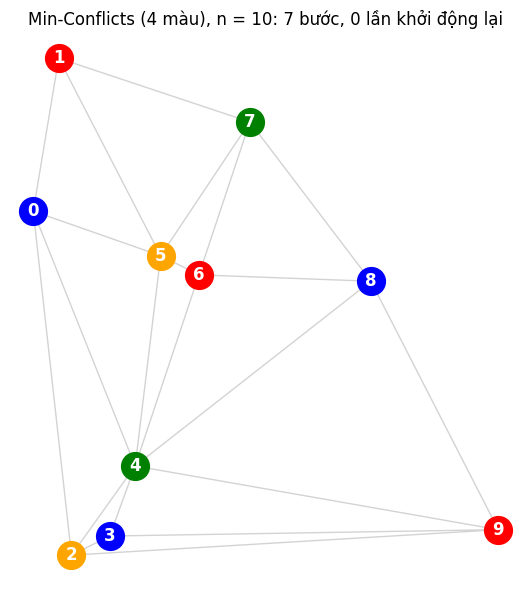

In [15]:
def min_conflicts(csp, max_steps=500, max_restarts=10, rng=None):
    rng = rng or random.Random(0)
    adj = adjacency(csp)
    vs = csp['variables']
    colors = csp['domains'][vs[0]]
    steps = improving = sideways = 0
    best_total, best_color = None, None
    t0 = time.perf_counter()
    for restart in range(max_restarts + 1):
        color = {v: rng.choice(colors) for v in vs}                                   # phép gán đầy đủ ngẫu nhiên
        conf = {v: sum(color[u] == color[v] for u in adj[v]) for v in vs}            # số láng giềng cùng màu
        total = sum(conf.values()) // 2                                               # số cạnh vi phạm
        if best_total is None or total < best_total:
            best_total, best_color = total, dict(color)
        for _ in range(max_steps):
            if total == 0:
                break
            v = rng.choice([x for x in vs if conf[x] > 0])                            # biến đang vi phạm
            cnt = {c: 0 for c in colors}
            for u in adj[v]:
                cnt[color[u]] += 1                                                    # xung đột nếu đổi sang màu c
            m = min(cnt.values())
            c_new = rng.choice([c for c in colors if cnt[c] == m])
            steps += 1
            if c_new != color[v]:
                delta = m - cnt[color[v]]                                             # thay đổi số cạnh vi phạm (<= 0)
                old = color[v]
                color[v] = c_new
                for u in adj[v]:
                    if color[u] == old: conf[u] -= 1
                    if color[u] == c_new: conf[u] += 1
                conf[v] = m
                total += delta
                if delta < 0: improving += 1
                else: sideways += 1
                if total < best_total:
                    best_total, best_color = total, dict(color)
        if total == 0:
            break
    dt = time.perf_counter() - t0
    return {'assignment': best_color, 'success': best_total == 0, 'conflicts': best_total,
            'steps': steps, 'improving': improving, 'sideways': sideways,
            'restarts': restart, 'time': dt}

mc = min_conflicts(csp, rng=random.Random(1))
print({k: (v if k != 'assignment' else '...') for k, v in mc.items()})
assert mc['success'] and complete(mc['assignment'], csp) and consistent(mc['assignment'], csp)
plot_graph(points, tri, mc['assignment'],
           title=f"Min-Conflicts (4 màu), n = {n}: {mc['steps']} bước, {mc['restarts']} lần khởi động lại")
save_fig('csp_03_to_mau_min_conflicts_4mau_n10.png')
plt.show()

### Khi 3 màu không đủ: vô nghiệm hay hết giới hạn?

Với 3 màu, đa số đồ thị Delaunay **vô nghiệm**. Có một chứng cứ toán học đơn giản: nếu một đỉnh *bên trong* (không nằm trên bao lồi) có **bậc lẻ**, các láng giềng của nó tạo thành một chu trình lẻ mà ở 3 màu bắt buộc phải xen kẽ đúng hai màu còn lại – điều không thể xảy ra với chu trình lẻ. Ta dùng chứng cứ này để *kiểm tra chéo* kết quả của các thuật toán, và minh họa trên một đồ thị $n = 20$:

* Backtracking/FC (thuật toán đầy đủ) duyệt hết và báo `unsat` → **chứng minh vô nghiệm**;
* Min-Conflicts thất bại sau nhiều lần khởi động lại → **chỉ có thể nói "không tìm thấy"**.

Đồ thị n = 20, 3 màu. Đỉnh trong có bậc lẻ: [11, 17, 18] -> chắc chắn vô nghiệm
FC + MRV + LCV  : unsat | COUNT = 28
Backtracking gốc: unsat | COUNT = 3745
Min-Conflicts   : success = False | số cạnh vi phạm tốt nhất = 2 | bước = 6600 | khởi động lại = 10


Đã lưu hình: figures/csp_04_to_mau_3mau_vo_nghiem_n20.png


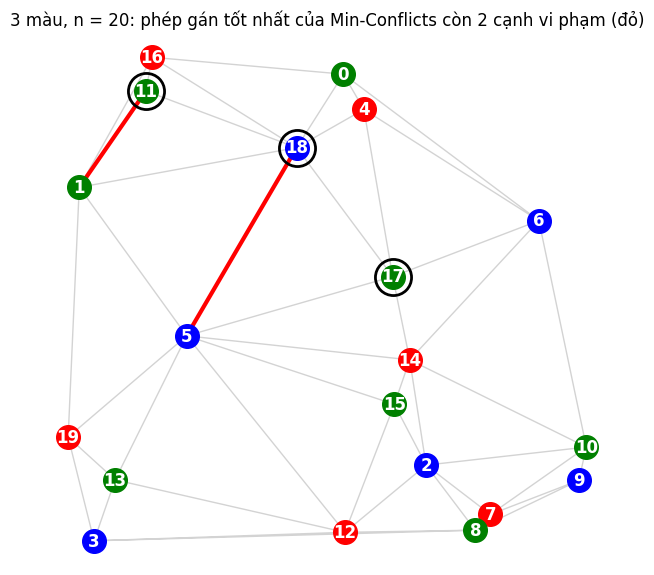

In [16]:
pts20, tri20, nb20 = make_instance(20, seed=20000, order='random')
csp20_3 = make_csp(nb20, COLORS3)
odd = odd_interior_vertices(tri20, nb20)
print('Đồ thị n = 20, 3 màu. Đỉnh trong có bậc lẻ:', odd, '-> chắc chắn vô nghiệm' if odd else '')

proof = solve(csp20_3, select_var=select_var_mrv, order_values=order_lcv, forward_checking=True, node_limit=None)
print('FC + MRV + LCV  :', proof['status'], '| COUNT =', proof['nodes'])
bt3 = solve(csp20_3, node_limit=20000)
print('Backtracking gốc:', bt3['status'], '| COUNT =', bt3['nodes'])

mc3 = min_conflicts(csp20_3, max_steps=600, max_restarts=10, rng=random.Random(5))
print('Min-Conflicts   : success =', mc3['success'], '| số cạnh vi phạm tốt nhất =', mc3['conflicts'],
      '| bước =', mc3['steps'], '| khởi động lại =', mc3['restarts'])

bad = [(a, b) for a, b in csp20_3['constraints']
       if mc3['assignment'][a] == mc3['assignment'][b]]
plot_graph(pts20, tri20, mc3['assignment'], bad_edges=bad, mark=odd, size=17,
           title=f"3 màu, n = 20: phép gán tốt nhất của Min-Conflicts còn {len(bad)} cạnh vi phạm (đỏ)")
save_fig('csp_04_to_mau_3mau_vo_nghiem_n20.png')
plt.show()

**Nhận xét.** Đồ thị $n=20$ có 3 đỉnh trong bậc lẻ (các đỉnh 11, 17, 18 được khoanh tròn), nên chắc chắn không tô được bằng 3 màu. Thuật toán đầy đủ **chứng minh** điều đó: FC + MRV + LCV kết thúc sau 28 nút, Backtracking gốc sau 3 745 nút. Min-Conflicts dùng 6 600 bước và 10 lần khởi động lại nhưng phép gán tốt nhất vẫn còn 2 cạnh vi phạm (màu đỏ trong hình): từ đó chỉ có thể kết luận "không tìm thấy nghiệm trong giới hạn đã cho", **không thể** kết luận vô nghiệm. Muốn phân biệt "hết giới hạn tính toán" với "chứng minh vô nghiệm" phải dùng thuật toán đầy đủ và kiểm tra trạng thái `unsat` (đã duyệt hết) so với `limit` (bị chặn bởi giới hạn nút).

## Thí nghiệm theo kích thước đồ thị

Với mỗi $n$ và số màu 3/4, ta sinh **20 đồ thị ngẫu nhiên** (seed `n*1000 + i`, cùng đồ thị cho mọi thuật toán và cho cả 3 và 4 màu) và chạy:

* 6 cấu hình backtracking: gốc, MRV, MRV+LCV, FC, FC+MRV, FC+MRV+LCV, với **giới hạn 20 000 nút** (để chạy trong thời gian hợp lý và phân biệt `unsat` với `limit`);
* Min-Conflicts với `max_steps = 30·n`, `max_restarts = 10`.

Thí nghiệm lặp lại với hai cách đánh số đỉnh: `x` (theo hoành độ, như notebook gốc) và `random` (ngẫu nhiên). Ghi nhận trạng thái, `COUNT`, số lần gán thử, thời gian, và cho mỗi đồ thị: số cạnh, số đỉnh bao lồi, có đỉnh trong bậc lẻ hay không.

In [17]:
N_LIST = [6, 10, 20, 40, 80, 120]
N_INST = 20
NODE_LIMIT = 20000
K_COLORS = {3: COLORS3, 4: COLORS4}

records, mc_records, graph_records = [], [], []
t_start = time.perf_counter()
for order in ['x', 'random']:
    for n_ in N_LIST:
        for i in range(N_INST):
            pts_, tri_, nbs_ = make_instance(n_, seed=n_ * 1000 + i, order=order)
            hull_size = len(set(int(v) for v in tri_.convex_hull.ravel()))
            odd_ = len(odd_interior_vertices(tri_, nbs_)) > 0
            n_edges = sum(len(x) for x in nbs_) // 2
            assert n_edges == 3 * n_ - 3 - hull_size           # hệ thức Euler cho phép tam giác hóa Delaunay
            graph_records.append({'order': order, 'n': n_, 'inst': i, 'edges': n_edges,
                                  'hull': hull_size, 'odd_interior': odd_})
            for k, cols in K_COLORS.items():
                csp_ = make_csp(nbs_, cols)
                for name, kw in ALL_CONFIGS.items():
                    r = solve(csp_, node_limit=NODE_LIMIT, **kw)
                    records.append({'order': order, 'k': k, 'n': n_, 'inst': i, 'algo': name,
                                    'status': r['status'], 'nodes': r['nodes'],
                                    'assigns': r['assigns'], 'time': r['time'], 'odd_interior': odd_})
                m = min_conflicts(csp_, max_steps=30 * n_, max_restarts=10, rng=random.Random(n_ * 1000 + i))
                mc_records.append({'order': order, 'k': k, 'n': n_, 'inst': i, 'success': m['success'],
                                   'conflicts': m['conflicts'], 'steps': m['steps'],
                                   'improving': m['improving'], 'sideways': m['sideways'],
                                   'restarts': m['restarts'], 'time': m['time']})
print(f'Hoàn tất thí nghiệm trong {time.perf_counter() - t_start:.1f} s')

df_rec = pd.DataFrame(records)
df_mc = pd.DataFrame(mc_records)
df_graph = pd.DataFrame(graph_records)
save_table(df_rec, 'csp_thuc_nghiem_backtracking_chi_tiet.csv')
save_table(df_mc, 'csp_thuc_nghiem_min_conflicts_chi_tiet.csv')

Hoàn tất thí nghiệm trong 72.1 s
Đã lưu bảng: results/csp_thuc_nghiem_backtracking_chi_tiet.csv
Đã lưu bảng: results/csp_thuc_nghiem_min_conflicts_chi_tiet.csv


### Kiểm tra tính đúng đắn của thí nghiệm

* Mọi nghiệm trả về đều đã được kiểm tra bằng `complete` + `consistent` (trong `solve` đã tái tạo `COUNT`; ở đây kiểm tra kết quả theo trạng thái).
* Với 3 màu: không thuật toán nào được báo `solution` trên đồ thị có đỉnh trong bậc lẻ.
* Các thuật toán đầy đủ **không bao giờ mâu thuẫn nhau**: nếu một thuật toán báo `unsat` thì không thuật toán nào báo `solution` trên cùng đồ thị.

In [18]:
# 1) 3 màu + có đỉnh trong bậc lẻ => không được có 'solution'
bad1 = df_rec[(df_rec.k == 3) & (df_rec.odd_interior) & (df_rec.status == 'solution')]
assert len(bad1) == 0

# 2) các thuật toán đầy đủ không mâu thuẫn nhau trên cùng đồ thị
g = df_rec.groupby(['order', 'k', 'n', 'inst']).status.agg(lambda s: set(s))
assert not any(('solution' in s) and ('unsat' in s) for s in g)

# 3) Min-Conflicts chỉ thành công khi bài toán thực sự có nghiệm (có thuật toán đầy đủ tìm được nghiệm)
sat_flag = df_rec.groupby(['order', 'k', 'n', 'inst']).status.agg(lambda s: 'solution' in set(s)).rename('sat')
df_mc = df_mc.join(sat_flag, on=['order', 'k', 'n', 'inst'])
assert not ((df_mc.success) & (~df_mc.sat)).any()

# 4) với 3 màu: số đồ thị có đỉnh trong bậc lẻ so với số đồ thị được chứng minh vô nghiệm bởi FC + MRV + LCV
chk = df_rec[(df_rec.k == 3) & (df_rec.algo == 'FC + MRV + LCV')]
print('Đồ thị 3 màu có đỉnh trong bậc lẻ                :', int(chk.odd_interior.sum()), '/', len(chk))
print('Đồ thị 3 màu bị FC+MRV+LCV chứng minh vô nghiệm   :', int((chk.status == 'unsat').sum()), '/', len(chk))
print('Đồ thị 3 màu bị chứng minh vô nghiệm nhưng KHÔNG có đỉnh trong bậc lẻ:',
      int(((chk.status == 'unsat') & (~chk.odd_interior)).sum()))
print('Mọi kiểm tra đều đạt.')

Đồ thị 3 màu có đỉnh trong bậc lẻ                : 210 / 240
Đồ thị 3 màu bị FC+MRV+LCV chứng minh vô nghiệm   : 210 / 240
Đồ thị 3 màu bị chứng minh vô nghiệm nhưng KHÔNG có đỉnh trong bậc lẻ: 0
Mọi kiểm tra đều đạt.


### Số cạnh trung bình theo $n$

Phép tam giác hóa Delaunay trên $n$ điểm có $3n - 3 - h$ cạnh ($h$ = số đỉnh trên bao lồi), đã được kiểm tra bằng `assert` ở trên.

In [19]:
df_edges = (df_graph[df_graph.order == 'random'].groupby('n')
            .agg(edges_tb=('edges', 'mean'), edges_min=('edges', 'min'), edges_max=('edges', 'max'),
                 hull_tb=('hull', 'mean')).reset_index())
df_edges['edges_tb'] = df_edges['edges_tb'].round(1)
df_edges['hull_tb'] = df_edges['hull_tb'].round(1)
df_edges['edges/n'] = (df_edges['edges_tb'] / df_edges['n']).round(2)
df_edges.columns = ['n', 'Số cạnh TB', 'Số cạnh min', 'Số cạnh max', 'Đỉnh bao lồi TB', 'Cạnh/đỉnh']
display(df_edges)
save_table(df_edges, 'csp_so_canh_trung_binh.csv')

,n,Số cạnh TB,Số cạnh min,Số cạnh max,Đỉnh bao lồi TB,Cạnh/đỉnh
0,6,10.2,9,12,4.8,1.70
1,10,21.2,20,23,5.8,2.12
2,20,49.3,47,51,7.7,2.46
3,40,107.6,105,112,9.4,2.69
4,80,225.6,220,229,11.4,2.82
5,120,344.2,341,347,12.8,2.87


Đã lưu bảng: results/csp_so_canh_trung_binh.csv


### Bảng kết quả theo thuật toán, số màu và $n$

* **Thành công (%)**: tỷ lệ đồ thị mà thuật toán tìm được nghiệm.
* **Vô nghiệm (%)**: tỷ lệ đồ thị mà thuật toán *chứng minh* vô nghiệm (chỉ thuật toán đầy đủ làm được).
* **Hết giới hạn (%)**: tỷ lệ chạm giới hạn 20 000 nút (chưa kết luận).
* **COUNT**: trung bình số nút trên 20 đồ thị (các lần chạm giới hạn được tính bằng 20 001 – là cận dưới).

In [20]:
def summarize(df):
    g = df.groupby(['order', 'k', 'n', 'algo'])
    out = g.agg(thanh_cong=('status', lambda s: 100 * (s == 'solution').mean()),
                vo_nghiem=('status', lambda s: 100 * (s == 'unsat').mean()),
                het_gioi_han=('status', lambda s: 100 * (s == 'limit').mean()),
                count_tb=('nodes', 'mean'), assigns_tb=('assigns', 'mean'),
                time_ms=('time', lambda s: 1000 * s.mean())).reset_index()
    return out

df_sum = summarize(df_rec)
df_mc_sum = (df_mc.groupby(['order', 'k', 'n'])
             .agg(thanh_cong=('success', lambda s: 100 * s.mean()),
                  co_nghiem=('sat', lambda s: 100 * s.mean()),
                  steps_tb=('steps', 'mean'), improving_tb=('improving', 'mean'),
                  sideways_tb=('sideways', 'mean'), restarts_tb=('restarts', 'mean'),
                  time_ms=('time', lambda s: 1000 * s.mean())).reset_index())
save_table(df_sum.round(3), 'csp_tong_hop_backtracking.csv')
save_table(df_mc_sum.round(3), 'csp_tong_hop_min_conflicts.csv')

ORDER_SHOW = 'random'
for k in [4, 3]:
    sub = df_sum[(df_sum.order == ORDER_SHOW) & (df_sum.k == k)]
    display(Markdown(f'**{k} màu – đánh số ngẫu nhiên – COUNT trung bình**'))
    display(sub.pivot(index='algo', columns='n', values='count_tb').reindex(list(ALL_CONFIGS)).round(1))
    display(Markdown(f'**{k} màu – đánh số ngẫu nhiên – tỷ lệ tìm được nghiệm (%) / chứng minh vô nghiệm (%) / hết giới hạn (%)**'))
    tb = sub.assign(ket_qua=lambda d: d.thanh_cong.round(0).astype(int).astype(str) + ' / ' +
                    d.vo_nghiem.round(0).astype(int).astype(str) + ' / ' +
                    d.het_gioi_han.round(0).astype(int).astype(str))
    display(tb.pivot(index='algo', columns='n', values='ket_qua').reindex(list(ALL_CONFIGS)))
    display(Markdown(f'**{k} màu – đánh số ngẫu nhiên – thời gian trung bình (ms)**'))
    display(sub.pivot(index='algo', columns='n', values='time_ms').reindex(list(ALL_CONFIGS)).round(3))

display(Markdown('**Min-Conflicts – đánh số ngẫu nhiên**'))
display(df_mc_sum[df_mc_sum.order == ORDER_SHOW].drop(columns='order').round(2))

display(Markdown('**Với đánh số theo hoành độ (như notebook gốc) – COUNT trung bình, 4 màu**'))
subx = df_sum[(df_sum.order == 'x') & (df_sum.k == 4)]
display(subx.pivot(index='algo', columns='n', values='count_tb').reindex(list(ALL_CONFIGS)).round(1))

Đã lưu bảng: results/csp_tong_hop_backtracking.csv
Đã lưu bảng: results/csp_tong_hop_min_conflicts.csv


**4 màu – đánh số ngẫu nhiên – COUNT trung bình**

n,6,10,20,40,80,120
algo,,,,,,
Backtracking (gốc),7.0,20.0,384.6,17121.8,20001.0,20001.0
+ MRV,7.0,11.0,22.6,44.8,103.2,362.2
+ LCV,7.0,19.7,371.7,14755.4,20001.0,20001.0
+ MRV + LCV,7.0,11.0,22.8,44.8,1139.4,2155.0
Forward Checking,7.0,14.7,69.3,7578.0,19126.2,20001.0
FC + MRV,7.0,11.0,22.3,43.8,98.2,318.4
FC + MRV + LCV,7.0,11.0,22.5,43.9,1129.8,2146.4


**4 màu – đánh số ngẫu nhiên – tỷ lệ tìm được nghiệm (%) / chứng minh vô nghiệm (%) / hết giới hạn (%)**

n,6,10,20,40,80,120
algo,,,,,,
Backtracking (gốc),100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,25 / 0 / 75,0 / 0 / 100,0 / 0 / 100
+ MRV,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0
+ LCV,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,45 / 0 / 55,0 / 0 / 100,0 / 0 / 100
+ MRV + LCV,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,95 / 0 / 5,90 / 0 / 10
Forward Checking,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,75 / 0 / 25,10 / 0 / 90,0 / 0 / 100
FC + MRV,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0
FC + MRV + LCV,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,100 / 0 / 0,95 / 0 / 5,90 / 0 / 10


...

n,6,10,20,40,80,120
algo,,,,,,
Backtracking (gốc),0.037,0.166,4.097,32.269,39.783,47.613
+ MRV,0.088,0.259,0.987,2.406,6.386,9.810
+ LCV,0.098,0.564,13.056,112.495,124.431,141.555
+ MRV + LCV,0.128,0.393,1.132,2.344,6.521,9.690
Forward Checking,0.042,0.142,0.977,28.113,81.751,95.967
FC + MRV,0.089,0.265,0.920,2.120,4.751,8.271
FC + MRV + LCV,0.122,0.349,1.120,2.229,4.875,8.704


**Min-Conflicts – đánh số ngẫu nhiên**

,k,n,thanh_cong,co_nghiem,steps_tb,improving_tb,sideways_tb,restarts_tb,time_ms
0,3,6,60.0,60.0,795.60,9.70,370.50,4.00,1.92
1,3,10,15.0,15.0,2810.80,41.80,800.10,8.50,6.57
2,3,20,0.0,0.0,6600.00,104.10,1100.75,10.00,18.85
3,3,40,0.0,0.0,13200.00,214.60,1634.70,10.00,47.77
4,3,80,0.0,0.0,26400.00,441.70,2693.35,10.00,121.37
5,3,120,0.0,0.0,39600.00,656.50,3908.55,10.00,249.39
6,4,6,100.0,100.0,3.15,2.35,0.70,0.00,0.03
7,4,10,100.0,100.0,9.80,3.90,3.60,0.00,0.05
8,4,20,100.0,100.0,36.35,9.05,16.20,0.00,0.18
9,4,40,100.0,100.0,500.75,25.70,151.85,0.25,1.90


**Với đánh số theo hoành độ (như notebook gốc) – COUNT trung bình, 4 màu**

n,6,10,20,40,80,120
algo,,,,,,
Backtracking (gốc),7.0,11.6,25.6,177.6,1031.8,2972.8
+ MRV,7.0,11.0,22.3,83.2,1091.8,3844.4
+ LCV,7.0,11.5,24.8,114.8,514.7,2509.5
+ MRV + LCV,7.0,11.0,21.8,82.2,196.4,2410.6
Forward Checking,7.0,11.2,22.4,49.9,175.6,501.6
FC + MRV,7.0,11.0,21.9,74.6,1088.6,3739.5
FC + MRV + LCV,7.0,11.0,21.6,73.9,179.8,2357.6


### Biểu đồ phân tích

Ba biểu đồ: **COUNT theo $n$**, **thời gian chạy theo $n$** và **tỷ lệ thành công / vô nghiệm theo $n$**; thêm một biểu đồ về chi phí của Min-Conflicts.

Đã lưu hình: figures/csp_05_count_theo_n.png


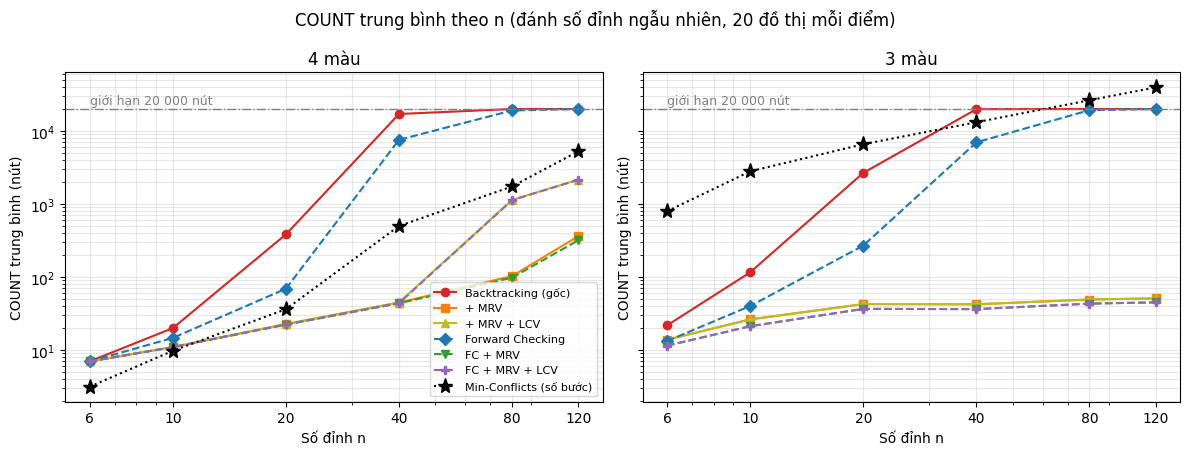

Đã lưu hình: figures/csp_06_thoi_gian_theo_n.png


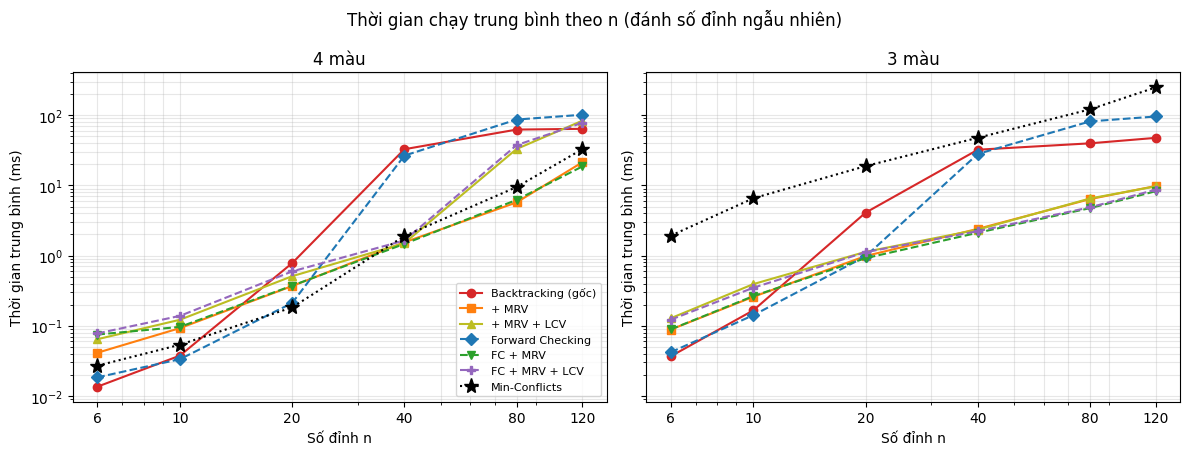

In [21]:
STYLE = {'Backtracking (gốc)': ('tab:red', 'o', '-'), '+ MRV': ('tab:orange', 's', '-'),
         '+ MRV + LCV': ('tab:olive', '^', '-'), 'Forward Checking': ('tab:blue', 'D', '--'),
         'FC + MRV': ('tab:green', 'v', '--'), 'FC + MRV + LCV': ('tab:purple', 'P', '--')}
algos_plot = ['Backtracking (gốc)', '+ MRV', '+ MRV + LCV', 'Forward Checking', 'FC + MRV', 'FC + MRV + LCV']

def draw_metric(ax, k, col, ylabel, logy=True, mc_col=None, mc_label=None, order='random'):
    sub = df_sum[(df_sum.order == order) & (df_sum.k == k)]
    for a in algos_plot:
        d = sub[sub.algo == a].sort_values('n')
        c, mk, ls = STYLE[a]
        ax.plot(d.n, d[col], marker=mk, linestyle=ls, color=c, label=a)
    if mc_col is not None:
        d = df_mc_sum[(df_mc_sum.order == order) & (df_mc_sum.k == k)].sort_values('n')
        ax.plot(d.n, d[mc_col], marker='*', markersize=11, linestyle=':', color='black', label=mc_label)
    ax.set_xscale('log'); ax.set_xlabel('Số đỉnh n')
    if logy: ax.set_yscale('log')
    ax.set_ylabel(ylabel); ax.set_xticks(N_LIST); ax.set_xticklabels(N_LIST)
    ax.grid(True, which='both', alpha=0.3); ax.set_title(f'{k} màu')

# --- Hình: COUNT theo n ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, k in zip(axes, [4, 3]):
    draw_metric(ax, k, 'count_tb', 'COUNT trung bình (nút)', mc_col='steps_tb', mc_label='Min-Conflicts (số bước)')
    ax.axhline(NODE_LIMIT, color='gray', linestyle='-.', linewidth=1)
    ax.text(N_LIST[0], NODE_LIMIT * 1.15, 'giới hạn 20 000 nút', color='gray', fontsize=9)
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle('COUNT trung bình theo n (đánh số đỉnh ngẫu nhiên, 20 đồ thị mỗi điểm)')
plt.tight_layout()
save_fig('csp_05_count_theo_n.png')
plt.show()

# --- Hình: thời gian theo n ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, k in zip(axes, [4, 3]):
    draw_metric(ax, k, 'time_ms', 'Thời gian trung bình (ms)', mc_col='time_ms', mc_label='Min-Conflicts')
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle('Thời gian chạy trung bình theo n (đánh số đỉnh ngẫu nhiên)')
plt.tight_layout()
save_fig('csp_06_thoi_gian_theo_n.png')
plt.show()

Đã lưu hình: figures/csp_07_ty_le_thanh_cong_vo_nghiem.png


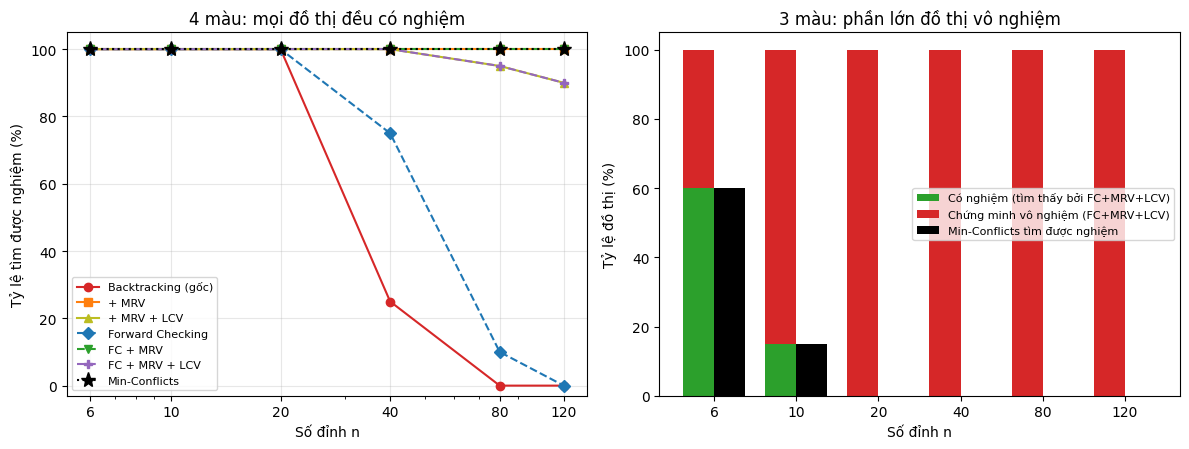

Đã lưu hình: figures/csp_08_min_conflicts_chi_phi.png


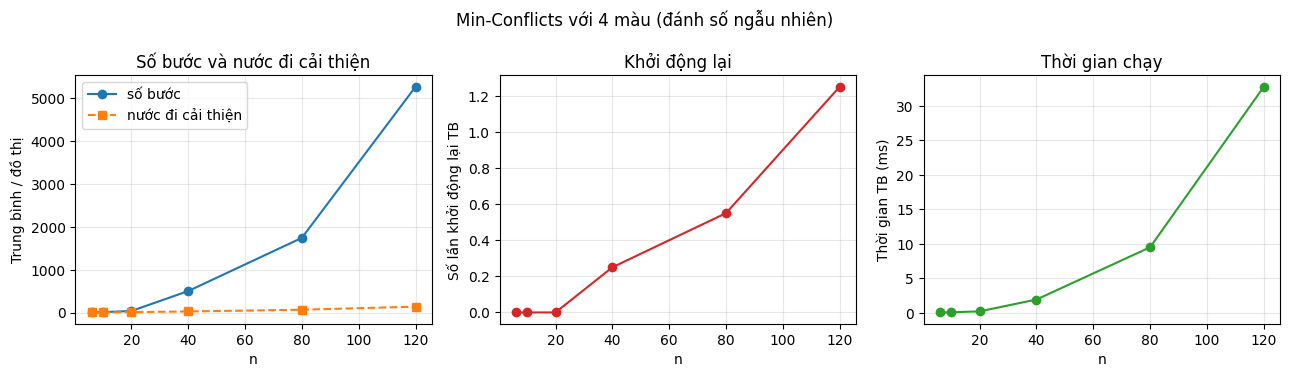

In [22]:
# --- Hình: tỷ lệ thành công / vô nghiệm ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
sub = df_sum[(df_sum.order == 'random') & (df_sum.k == 4)]
for a in algos_plot:
    d = sub[sub.algo == a].sort_values('n')
    c, mk, ls = STYLE[a]
    ax.plot(d.n, d.thanh_cong, marker=mk, linestyle=ls, color=c, label=a)
d = df_mc_sum[(df_mc_sum.order == 'random') & (df_mc_sum.k == 4)].sort_values('n')
ax.plot(d.n, d.thanh_cong, marker='*', markersize=11, linestyle=':', color='black', label='Min-Conflicts')
ax.set_xscale('log'); ax.set_xticks(N_LIST); ax.set_xticklabels(N_LIST)
ax.set_xlabel('Số đỉnh n'); ax.set_ylabel('Tỷ lệ tìm được nghiệm (%)'); ax.set_ylim(-3, 105)
ax.set_title('4 màu: mọi đồ thị đều có nghiệm'); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
sub = df_sum[(df_sum.order == 'random') & (df_sum.k == 3)]
best = sub[sub.algo == 'FC + MRV + LCV'].sort_values('n')
w = 0.38
x = np.arange(len(N_LIST))
ax.bar(x - w / 2, best.thanh_cong.values, w, color='tab:green', label='Có nghiệm (tìm thấy bởi FC+MRV+LCV)')
ax.bar(x - w / 2, best.vo_nghiem.values, w, bottom=best.thanh_cong.values, color='tab:red',
       label='Chứng minh vô nghiệm (FC+MRV+LCV)')
dm = df_mc_sum[(df_mc_sum.order == 'random') & (df_mc_sum.k == 3)].sort_values('n')
ax.bar(x + w / 2, dm.thanh_cong.values, w, color='black', label='Min-Conflicts tìm được nghiệm')
ax.set_xticks(x); ax.set_xticklabels(N_LIST)
ax.set_xlabel('Số đỉnh n'); ax.set_ylabel('Tỷ lệ đồ thị (%)'); ax.set_ylim(0, 105)
ax.set_title('3 màu: phần lớn đồ thị vô nghiệm'); ax.legend(fontsize=8, loc='center right')
plt.tight_layout()
save_fig('csp_07_ty_le_thanh_cong_vo_nghiem.png')
plt.show()

# --- Hình: chi phí Min-Conflicts (4 màu) ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
d = df_mc_sum[(df_mc_sum.order == 'random') & (df_mc_sum.k == 4)].sort_values('n')
axes[0].plot(d.n, d.steps_tb, 'o-', label='số bước')
axes[0].plot(d.n, d.improving_tb, 's--', label='nước đi cải thiện')
axes[0].set_xlabel('n'); axes[0].set_ylabel('Trung bình / đồ thị'); axes[0].set_title('Số bước và nước đi cải thiện')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(d.n, d.restarts_tb, 'o-', color='tab:red')
axes[1].set_xlabel('n'); axes[1].set_ylabel('Số lần khởi động lại TB'); axes[1].set_title('Khởi động lại')
axes[1].grid(True, alpha=0.3)
axes[2].plot(d.n, d.time_ms, 'o-', color='tab:green')
axes[2].set_xlabel('n'); axes[2].set_ylabel('Thời gian TB (ms)'); axes[2].set_title('Thời gian chạy')
axes[2].grid(True, alpha=0.3)
fig.suptitle('Min-Conflicts với 4 màu (đánh số ngẫu nhiên)')
plt.tight_layout()
save_fig('csp_08_min_conflicts_chi_phi.png')
plt.show()

**Nhận xét kết quả thí nghiệm** (20 đồ thị mỗi điểm, đánh số đỉnh ngẫu nhiên, giới hạn 20 000 nút).

*Số cạnh.* Số cạnh trung bình tăng gần tuyến tính theo $n$ (10 cạnh ở $n=6$; 21,2 ở $n=10$; 107,6 ở $n=40$; 344,2 ở $n=120$), tiệm cận $\approx 3n$ vì mỗi phép tam giác hóa có $3n-3-h$ cạnh.

*4 màu* (mọi đồ thị phẳng đều tô được 4 màu theo Định lý bốn màu):

* **Backtracking gốc** bùng nổ rất nhanh: `COUNT` trung bình 20 (n=10), 385 (n=20), 17 122 (n=40) và chạm giới hạn ở $n \ge 80$ (tỷ lệ thành công tụt từ 100 % xuống 25 % ở $n=40$ và 0 % ở $n \ge 80$). Forward Checking thuần tốt hơn nhưng cũng sụp đổ ở $n \ge 80$ (thành công 10 % ở $n=80$, 0 % ở $n=120$).
* **MRV** và **FC + MRV** tăng gần tuyến tính: `COUNT` khoảng 11, 23, 45, 103, 362 (MRV) và 318 (FC + MRV) tại $n = 10, 20, 40, 80, 120$; thành công 100 % ở mọi $n$. Thứ tự chọn biến là yếu tố quyết định, FC cộng thêm lợi ích nhỏ.
* **LCV** làm kết quả **xấu đi**: MRV + LCV có `COUNT` trung bình 1 139 và 2 155 ở $n=80, 120$ và chỉ thành công 95 % và 90 % (5–10 % đồ thị chạm giới hạn) – một vài đồ thị làm LCV dẫn vào nhánh sai, tạo ra đuôi phân phối nặng.
* **Thời gian:** ở $n \le 10$ cấu hình đơn giản nhất nhanh nhất vì mỗi nút rẻ (ví dụ n=10: 0,04 ms so với 0,09 ms của MRV); từ $n \ge 20$ các heuristic thắng (n=40: FC + MRV 1,5 ms so với ≈ 33 ms của bản gốc, vốn đã chạm giới hạn).
* **Min-Conflicts** thành công **100 %** ở mọi $n$ với số bước trung bình khoảng 10 (n=10), 36 (n=20), 501 (n=40), 1 742 (n=80), 5 264 (n=120) và hầu như không cần khởi động lại (0–1,25 lần mỗi đồ thị). Tìm kiếm cục bộ rất thích hợp cho bài toán có nhiều nghiệm; chi phí tăng nhanh hơn tuyến tính một chút theo $n$.

*3 màu:* tỷ lệ đồ thị có nghiệm giảm rất nhanh: 60 % ($n=6$), 15 % ($n=10$) và **0 % từ $n \ge 20$**.

* Ở $n \ge 40$, **MRV và FC + MRV chứng minh vô nghiệm 100 % số đồ thị chỉ với 36–51 nút**, còn Backtracking gốc chỉ chứng minh được 5 % ở $n=40$ và **0 % ở $n \ge 80$ (hết giới hạn 20 000 nút)**. Đây là minh họa trực tiếp cho sự khác nhau giữa "chưa kết luận vì hết giới hạn" và "đã chứng minh vô nghiệm".
* Kiểm tra chéo: 210 trong 240 đồ thị 3 màu có đỉnh trong bậc lẻ và **đúng 210** đồ thị đó được chứng minh vô nghiệm; 30 đồ thị còn lại (không có đỉnh bậc lẻ) đều tô được. Mọi thuật toán đầy đủ đều đồng ý với nhau.
* **Min-Conflicts** thành công đúng bằng tỷ lệ đồ thị có nghiệm (60 % ở $n=6$, 15 % ở $n=10$), và thất bại ở những đồ thị vô nghiệm bằng cách dùng hết ngân sách (11 lần thử × $30n$ bước).

*Hạn chế quan trọng của kết luận.* Với cách đánh số đỉnh **theo hoành độ** (notebook gốc), Backtracking gốc đã chạy rất tốt (thành công 100 % đến $n=80$) vì thứ tự quét trái–phải giữ "đường biên" tô màu rất hẹp, còn MRV lại *kém hơn* (thành công 85 % ở $n=120$) vì nó nhảy khắp đồ thị và tạo nhiều biên cùng lúc; trong trường hợp đó Forward Checking thuần là tốt nhất (100 %). Kết luận "MRV tốt hơn" vì vậy phụ thuộc vào thứ tự đánh số đỉnh và loại đồ thị.

## Bảng ghi kết quả thí nghiệm (theo mẫu mục 4.2 của đề Lab)

Số liệu là trung bình trên **20 đồ thị ngẫu nhiên** (đánh số ngẫu nhiên, seed `n*1000 + i`). Thành công (%) là tỷ lệ tìm được nghiệm; "Xung đột / COUNT" là COUNT (thuật toán backtracking) hoặc số bước (Min-Conflicts) – hai đại lượng **không đồng nhất** nên không so sánh trực tiếp với nhau.

In [23]:
def pick(algo, k, n_):
    r = df_sum[(df_sum.order == 'random') & (df_sum.algo == algo) & (df_sum.k == k) & (df_sum.n == n_)].iloc[0]
    return r

rows = []
for algo, label in [('Backtracking (gốc)', 'Backtracking'), ('+ MRV', 'MRV + Backtracking'),
                    ('Forward Checking', 'Forward Checking'), ('FC + MRV', 'FC + MRV')]:
    for k in [4, 3]:
        r = pick(algo, k, 10)
        rows.append({'Bài toán': 'Tô màu', 'Kích thước': 'n = 10', 'Thuật toán': label, 'Số màu': k,
                     'Thành công (%)': round(r.thanh_cong, 1), 'Xung đột / COUNT': round(r.count_tb, 1),
                     'Thời gian (s)': round(r.time_ms / 1000, 6)})
for n_ in [10, 40, 120]:
    for k in [4, 3]:
        r = df_mc_sum[(df_mc_sum.order == 'random') & (df_mc_sum.k == k) & (df_mc_sum.n == n_)].iloc[0]
        rows.append({'Bài toán': 'Tô màu', 'Kích thước': f'n = {n_}', 'Thuật toán': 'Min-Conflicts', 'Số màu': k,
                     'Thành công (%)': round(r.thanh_cong, 1), 'Xung đột / COUNT': round(r.steps_tb, 1),
                     'Thời gian (s)': round(r.time_ms / 1000, 6)})
df_table42_csp = pd.DataFrame(rows)
display(df_table42_csp)
save_table(df_table42_csp, 'csp_bang_4_2_tong_hop.csv')

,Bài toán,Kích thước,Thuật toán,Số màu,Thành công (%),Xung đột / COUNT,Thời gian (s)
0,Tô màu,n = 10,Backtracking,4,100.0,20.0,0.000038
1,Tô màu,n = 10,Backtracking,3,15.0,116.5,0.000166
2,Tô màu,n = 10,MRV + Backtracking,4,100.0,11.0,0.000093
3,Tô màu,n = 10,MRV + Backtracking,3,15.0,26.4,0.000259
4,Tô màu,n = 10,Forward Checking,4,100.0,14.7,0.000033
5,Tô màu,n = 10,Forward Checking,3,15.0,40.2,0.000142
6,Tô màu,n = 10,FC + MRV,4,100.0,11.0,0.000096
7,Tô màu,n = 10,FC + MRV,3,15.0,21.2,0.000265
8,Tô màu,n = 10,Min-Conflicts,4,100.0,9.8,0.000054
9,Tô màu,n = 10,Min-Conflicts,3,15.0,2810.8,0.006565


Đã lưu bảng: results/csp_bang_4_2_tong_hop.csv


# Kết luận chung (phần tô màu đồ thị)

* **Biểu diễn:** bài toán tô màu đồ thị được mô hình hóa gọn bằng $(X, D, C)$ với ràng buộc nhị phân "khác màu"; cần phân biệt phép gán *đầy đủ*, *hợp lệ* và *nghiệm* (đầy đủ và hợp lệ). Trên đồ thị $n=10$ chỉ có 480 trong $4^{10}$ phép gán đầy đủ là nghiệm.
* **Tìm kiếm có hệ thống:** MRV mang lại cải thiện lớn nhất (từ chạm giới hạn 20 000 nút xuống 41 nút ở $n=40$); Forward Checking cắt nhánh sớm nhưng phải trả chi phí quản lý miền; LCV không giúp (thậm chí làm xấu đi) trong bài toán này.
* **Tìm kiếm cục bộ:** Min-Conflicts giải được 100 % đồ thị 4 màu đến $n=120$ với chi phí thấp, nhưng khi vô nghiệm (3 màu) nó chỉ thất bại mà không chứng minh được gì.
* **Vô nghiệm và hết giới hạn:** chỉ thuật toán đầy đủ duyệt hết mới chứng minh được vô nghiệm; trạng thái `limit` khác `unsat`. Với 3 màu, chứng cứ đỉnh trong bậc lẻ cho phép kiểm tra chéo kết quả.
* **Lưu ý khi đánh giá thực nghiệm:** kết quả phụ thuộc vào cách đánh số đỉnh, giới hạn nút, tập đồ thị (20 mỗi điểm) và hạt giống; thời gian đo bằng Python nên còn phụ thuộc cài đặt và máy chạy. Vì vậy cần cố định seed khi so sánh và lặp nhiều đồ thị ngẫu nhiên.